# Modelado experimental

## Criterios de evaluación y selección de modelos

En este proyecto, se asumirá una relación de importancia entre las clases del 70 % para la clase positiva (suscripción) y del 30 % para la clase negativa (no suscripción). Se considera que el costo asociado a un falso negativo (FN), es decir, no identificar a un cliente que se suscribiría, es superior al de un falso positivo (FP), que consiste en predecir una suscripción cuando esta no se produce. El objetivo es que el modelo sea eficaz tanto en la identificación y segmentación de estos clientes. 

1. Se priorizará el Recall como métrica principal de evaluación, con el objetivo de maximizar especialmente la proporción de suscripciones potenciales correctamente identificadas y reducir la cantidad de falsos negativos.

2. Como métrica complementaria, se utilizará el área bajo la curva Precision-Recall (PR-AUC), que permitirá evaluar la relación entre Precision y Recall a distintos umbrales de clasificación, considerando el impacto de los falsos positivos sobre la calidad de las predicciones positivas.

3. Desde una perspectiva de negocio, se analizará el costo asociado a cada modelo utilizando el umbral de clasificación predeterminado de 0.5. Este análisis permitirá comparar los modelos no solo por su capacidad predictiva, sino también por su adecuación a los costos del problema. Al mismo tiempo que se priorizara modelos interpretables, para poder tener una comprensión diagnostica inicial de posibles causas asociadas a este segmento de los usuarios.


## Librerías

In [1]:
import os
import sys
import warnings

warnings.filterwarnings(
    "ignore",
    category=Warning,
    module="pandas",
)

# Agrega el directorio padre (raíz del proyecto) al path de Python
sys.path.append(os.path.abspath(os.path.join('..')))

In [2]:
import pprint

In [3]:
# ============================================================
# 1. MANIPULACIÓN Y ANÁLISIS DE DATOS
# ============================================================

import numpy as np
import pandas as pd

In [4]:
# ============================================================
# 2. VISUALIZACIÓN DE DATOS
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns
import graphviz
from IPython.display import Image

In [5]:
# ============================================================
# 3. Pruebas estadisticas
# ============================================================

import scipy.stats as stats
from sklearn.feature_selection import chi2
from scipy.stats import chi2_contingency

In [ ]:
# ============================================================
# 4. MODELOS DE MACHINE LEARNING
# ============================================================
from sklearn.linear_model import ElasticNet

from sklearn.ensemble import (
    RandomForestRegressor,
)

from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.neural_network import MLPRegressor
from lightgbm import LGBMRegressor

from sklearn.tree import (
    DecisionTreeRegressor,
    plot_tree,
    export_text,
    export_graphviz,
    _tree
)

from xgboost import XGBRegressor

In [62]:
# ============================================================
# 5. SELECCIÓN, VALIDACIÓN Y AJUSTE DE MODELOS
# ============================================================

from sklearn.base import clone

from sklearn.pipeline import Pipeline

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer

from src.cronological_split import chronological_panel_train_test_split, ChronologicalPanelSplitCV

from src.experiment_factory import ExperimentFactory
from src.model_optimizer import ModelOptimizer
from src.experiment_evaluator import ExperimentEvaluator
from src.experiment_tracker import ExperimentTracker

In [9]:
# ============================================================
# 9. FUNCIONES Y TRANSFORMACIONES PROPIAS
# ============================================================

from src.custom_standarization_classes_and_functions import GeneralPreprocessor

## Funciones complementarias:

In [11]:
# Función RMSPE
def rmspe(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    mask = y_true != 0
    return np.sqrt(
        np.mean(
            ((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2
        )
    )

In [12]:
# Define funciones nombradas (globales)
def get_week_of_year(x):
    return x.dt.isocalendar().week.astype(int)

def get_quarter(x):
    return x.dt.quarter

def get_is_weekend(x):
    return (x.dt.dayofweek >= 5).astype('category')

def get_month(x):
    return x.dt.month.astype('category')

In [13]:
def convert_to_array(X):
    return np.asarray(X)

## Importación de datos

In [14]:
df_ml_path = '../data/1_bronze/df.csv'
df_ml = pd.read_csv(df_ml_path)
df_ml.sample(5)

,Unnamed: 0,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
54283,54283,60,6,2014-02-01,5389,454,1,0,0,0,d,c,5540.0,10.0,2009.0,0,NaN,NaN,NaN
843516,843516,926,5,2013-09-13,7795,582,1,1,0,0,d,c,5150.0,3.0,2011.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
730130,730130,802,1,2015-06-01,10953,682,1,1,0,0,a,c,910.0,NaN,NaN,1,22.0,2011.0,"Feb,May,Aug,Nov"
240736,240736,265,2,2013-09-03,3909,449,1,0,0,0,a,a,4580.0,NaN,NaN,1,14.0,2015.0,"Jan,Apr,Jul,Oct"
305639,305639,336,1,2014-01-20,19208,2397,1,1,0,0,a,a,190.0,7.0,2014.0,0,NaN,NaN,NaN


### Separación de datos

In [15]:
#top_columns = joblib.load('../artifacts/top_columns.joblib')
#top_columns

#### `X` e `y` y `Train`-`test`

In [16]:
X_train, X_test, y_train, y_test = chronological_panel_train_test_split(
    df_ml, 
    target_col= 'Sales',
    test_days=None, 
    test_size=0.3, 
    filter_open_train=False
)

[ChronologicalPanelSplit] Fecha de corte: 2014-10-22
Train: 2013-01-01 -> 2014-10-22 | Shape X: (715379, 18)
Test:  2014-10-23 -> 2015-07-31 | Shape X: (301830, 18)


Samples:

In [ ]:
#SAMPLE_SIZE = min(50000, len(X_train))
#X_train = X_train.sample(n=SAMPLE_SIZE, random_state=42)
#y_train = y_train.loc[X_train.index]

## Instanciación y creación de la grilla de hiperparámetros mediante GridSearchCV

En el análisis bivariado no se observaron relaciones lineales claras entre las características y la variable objetivo. Sin embargo, antes de descartar la existencia de relaciones lineales, que puedan manifestarse más allá de las asociaciones bivariadas, se explorarán distintas estrategias de reducción de dimensionalidad y modelado (incluyendo modelos de clasificación lineales y no lineales robustos, y/o con mecanismos de regularización o control de la varianza de las predicciones), teniendo en cuenta el tamaño relativamente reducido de la muestra. 

### Metodos de reducción:

In [31]:
reductions = {
    "options": {
        "Sin reducción": "passthrough",
    },

    "grids": {
        "Sin reducción": {},
    }
}

### Modelos base

* ElasticNet
* Árbol de decisión individual

#### ElasticNet

In [18]:
elasticnet = ElasticNet(
    max_iter=3000,
    random_state=42
)

grid_elasticnet = {
    "alpha": [0.001, 0.01, 0.1, 1, 10, 100],
    "l1_ratio": [0.1, 0.3, 0.5, 0.7, 0.9],
}

#### Arbol individual (con inyección de coste hipotetico de 0.4 para no subscritos y 0.6 para predecir subscriptos.)

In [19]:
decision_tree = DecisionTreeRegressor(
    random_state=42
)

grid_decision_tree = {
    # Control de profundidad
    "max_depth": [3, 5, 7, 9],
    # Fracción mínima de muestras para dividir un nodo
    "min_samples_split": [0.007, 0.01, 0.02, 0.05, 0.10],
    # Fracción mínima de muestras por hoja
    "min_samples_leaf": [0.01, 0.02, 0.05, 0.10],
    # Poda del árbol
    "ccp_alpha": [0.0, 0.001, 0.01],
    # Reducción mínima de impureza para dividir
    "min_impurity_decrease": [0.0005, 0.001, 0.005, 0.01, 0.015],
    # Criterios de división
    "criterion": ["squared_error", "absolute_error"]
}

### Modelos avanzados: ensamblados y redes neuronales

* Random Forest.
* XGBoost.
* MLP.

#### Random Forest

In [20]:
random_forest = RandomForestRegressor(
    random_state=42,
    n_jobs=1
)
grid_random_forest = {
    "n_estimators": [200, 500],
    "max_depth": [None, 10, 7],
    "min_samples_leaf": [1, 2, 5],
    "max_features": ["sqrt", 0.5]
}

#### XGBoost

In [21]:
xgboost = XGBRegressor(
    random_state=42,
    eval_metric="rmse",
    objective="reg:squarederror",
    n_jobs=1
)
grid_xgboost = {
    "n_estimators": [200, 500, 800, 1000],
    "max_depth": [2, 3, 4, 5, 6, 8],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 0.01, 0.1, 1],
    "reg_lambda": [1, 5, 10],
    "gamma": [0, 0.01, 0.1, 1],
}

#### MLP

In [22]:
mlp = MLPRegressor(
    max_iter=500,
    early_stopping=True,
    random_state=42
)
grid_mlp = {
    "hidden_layer_sizes": [
        (50,),
        (100,),
        (100, 50)
    ],
    "activation": ["relu", "tanh"],
    "alpha": [0.0001, 0.001, 0.01],
    "learning_rate_init": [0.001, 0.01]
}

### Combinaciones de modelos y grillas de hiperparámetros:

In [23]:
models = {
    "options": {
        #"ElasticNet": elasticnet,
        "DTR": decision_tree,
        #"RFR": random_forest,
        "XGBR": xgboost,
        #"MLP": mlp
    },

    "grids": {
        #"ElasticNet": grid_elasticnet,
        "DTR": grid_decision_tree,
        #"RFR": grid_random_forest,
        "XGBR": grid_xgboost,
        #"MLP": grid_mlp
    },
}

#### Carga de artefactos:

In [24]:
preprocessor = joblib.load('../artifacts/pipeline_preprocessing_fe.joblib')

#### Pipeline:

Columnas con mayor feature importance en iteraciones previas:

In [64]:
columns = [
    'open',
    'promo',
    'store',
    'dayofweek',
    'month',
    'competitiondistance',
    'competitionopensincemonth'
]

Construcción del pipeline final:

In [69]:
pipeline = Pipeline([
    ("preprocessor", clone(preprocessor)),
    ("selection", ColumnTransformer(
        transformers=[
            ("select", "passthrough", columns)
        ],
        remainder="drop",
        verbose_feature_names_out=False
    )),
    ("reduction", "passthrough"),
    ("model", clone(decision_tree))
])

### Combinaciones de experimentos: estrategias de reducción de dimensionalidad × estrategias de modelado × hiperparámetros.

In [70]:
factory = ExperimentFactory(
    models=models,
    reductions=reductions,
)

experiments = factory.generate()

for experiment in experiments:
    print(f"Modelo: {experiment['nombre_modelo']}")
    print(f"Reducción: {experiment['reduccion']}")
    print(f"Grid: {experiment['param_grid']}")
    print("-" * 60)

Modelo: DTR
Reducción: Sin reducción
Grid: {'model__max_depth': [3, 5, 7, 9], 'model__min_samples_split': [0.007, 0.01, 0.02, 0.05, 0.1], 'model__min_samples_leaf': [0.01, 0.02, 0.05, 0.1], 'model__ccp_alpha': [0.0, 0.001, 0.01], 'model__min_impurity_decrease': [0.0005, 0.001, 0.005, 0.01, 0.015], 'model__criterion': ['squared_error', 'absolute_error'], 'reduction': ['passthrough'], 'model': [DecisionTreeRegressor(random_state=42)]}
------------------------------------------------------------
Modelo: XGBR
Reducción: Sin reducción
Grid: {'model__n_estimators': [200, 500, 800, 1000], 'model__max_depth': [2, 3, 4, 5, 6, 8], 'model__learning_rate': [0.01, 0.03, 0.05, 0.1], 'model__subsample': [0.6, 0.8, 1.0], 'model__colsample_bytree': [0.6, 0.8, 1.0], 'model__reg_alpha': [0, 0.01, 0.1, 1], 'model__reg_lambda': [1, 5, 10], 'model__gamma': [0, 0.01, 0.1, 1], 'reduction': ['passthrough'], 'model': [XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=Non

### Entrenamiento y optimización con GridSearchCV

In [71]:
cv = ChronologicalPanelSplitCV(
    n_splits=5,
    test_size=30,
    min_train_size=180,
    date_col='Date',
    gap=0,
    verbose=False
)

In [ ]:
optimizer = ModelOptimizer(
    pipeline=pipeline,
    cv=5,
    scoring="r2",
    search_type="random",
    n_iter=50,
    random_state=42,
    n_jobs=-1,
    verbose=0,
)

optimizer.fit(
    experiments=experiments,
    X=X_train,
    y=y_train,

)

### Evaluación general

In [73]:
def rmspe(y_true, y_pred):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)

    mask = y_true != 0

    return np.sqrt(
        np.mean(
            ((y_true[mask] - y_pred[mask]) / y_true[mask]) ** 2
        )
    )

In [74]:
results = optimizer.get_results()

display(results)

,Modelo,Reducción,Método búsqueda,Mejor score CV,Score entrenamiento CV,Desviación score CV,Brecha train-CV,Mejores parámetros
0,XGBR,Sin reducción,random,0.908316,0.946482,0.002821,0.038166,"{'reduction': 'passthrough', 'model__subsample..."
1,DTR,Sin reducción,random,0.842636,0.852377,0.003986,0.009741,"{'reduction': 'passthrough', 'model__min_sampl..."


---

## Modelos individuales:

- DecisionTreeRegressor
- XGBoostRegressor



### Pipeline XGBRegressor:

In [75]:
pipeline_xgb_sin_reduccion = optimizer.search_objects['XGBR', 'Sin reducción'].best_estimator_
pipeline_xgb_sin_reduccion

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Unnamed: 0','Store','DayOfWeek',...,'Promo2SinceWeek','Promo2SinceYear', 'PromoInterval']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('gp_step', ...), ('general_preprocessing', ...), ...]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline canno

In [76]:
xgbr_sin_reduccion = pipeline_xgb_sin_reduccion.named_steps['model']

#### Evaluación individual

<Axes: >

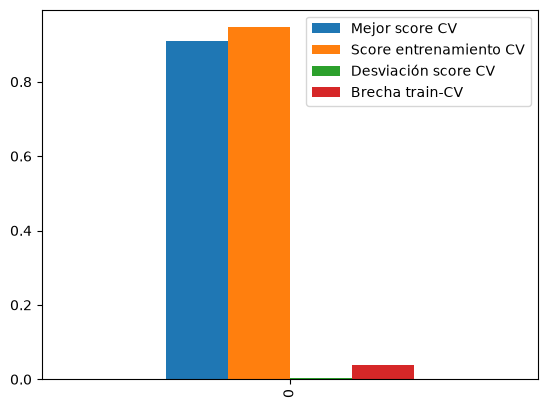

In [77]:
results[(results['Modelo']=='XGBR') & (results['Reducción']=='Sin reducción')].plot(kind='bar')

##### Interpretabilidad individual

In [82]:
nombres_variables = (

    pipeline_xgb_sin_reduccion
    .named_steps["selection"]
    .get_feature_names_out()

)

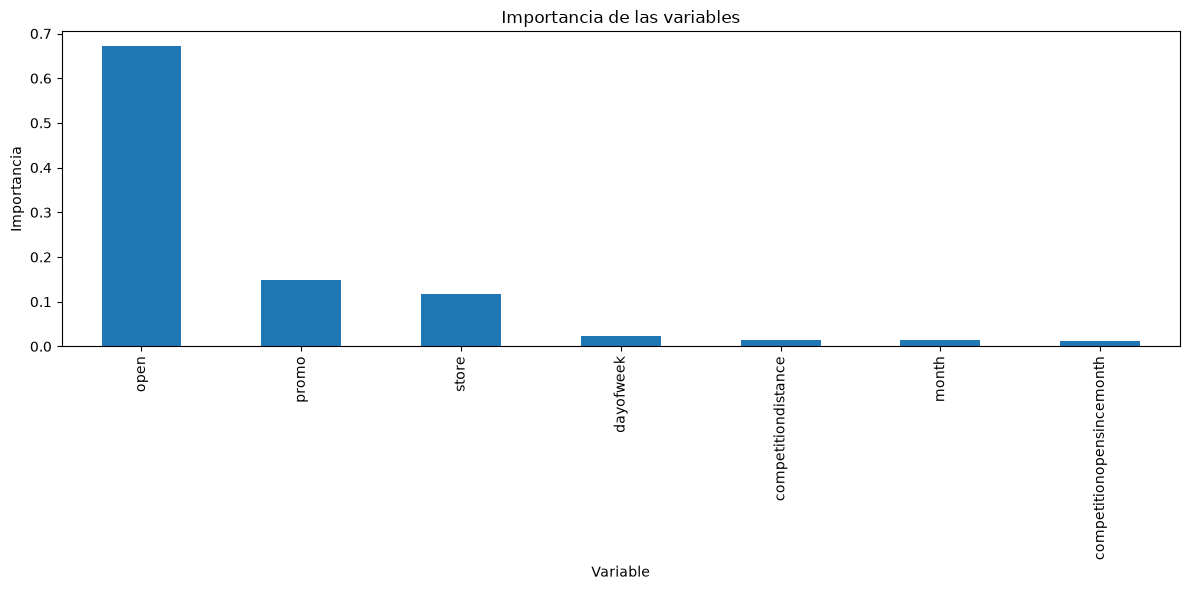

In [84]:
feature_importance = pd.DataFrame({
    "Variable": nombres_variables,
    "Importancia": xgbr_sin_reduccion.feature_importances_,
}).sort_values(
    "Importancia",
    ascending=False,
)

feature_importance.plot(
    kind='bar',
    x='Variable',
    y='Importancia',
    figsize=(12, 6),
    legend=False
)

plt.xticks(rotation=90)
plt.ylabel('Importancia')
plt.title('Importancia de las variables')
plt.tight_layout()
plt.show()

### Pipeline DecisionTreeRegressor:

In [88]:
pipeline_decision_tree_sin_reduccion = optimizer.search_objects['DTR', 'Sin reducción'].best_estimator_
pipeline_decision_tree_sin_reduccion

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('selection', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](18,)","['Unnamed: 0','Store','DayOfWeek',...,'Promo2SinceWeek','Promo2SinceYear', 'PromoInterval']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,18
,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('gp_step', ...), ('general_preprocessing', ...), ...]"
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",True
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline canno

In [89]:
decision_tree_sin_reduccion = pipeline_decision_tree_sin_reduccion.named_steps['model']

#### Evaluación individual

<Axes: >

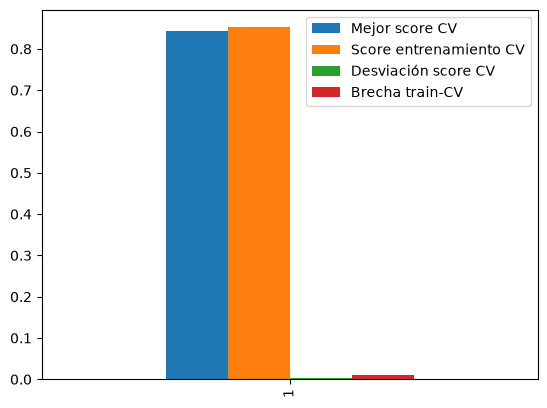

In [90]:
results[(results['Modelo']=='DTR') & (results['Reducción']=='Sin reducción')].plot(kind='bar')

##### Interpretabilidad individual

In [91]:
nombres_variables = (

    pipeline_decision_tree_sin_reduccion
    .named_steps["selection"]
    .get_feature_names_out()

)

In [92]:
feature_importance = pd.DataFrame({

    "Variable": nombres_variables,
    "Importancia": decision_tree_sin_reduccion.feature_importances_,

}).sort_values(

    "Importancia",
    ascending=False,

)

print(feature_importance)

                    Variable  Importancia
0                       open     0.515414
2                      store     0.335898
1                      promo     0.119762
3                  dayofweek     0.027597
5        competitiondistance     0.000893
6  competitionopensincemonth     0.000306
4                      month     0.000130


Importancia de variables:

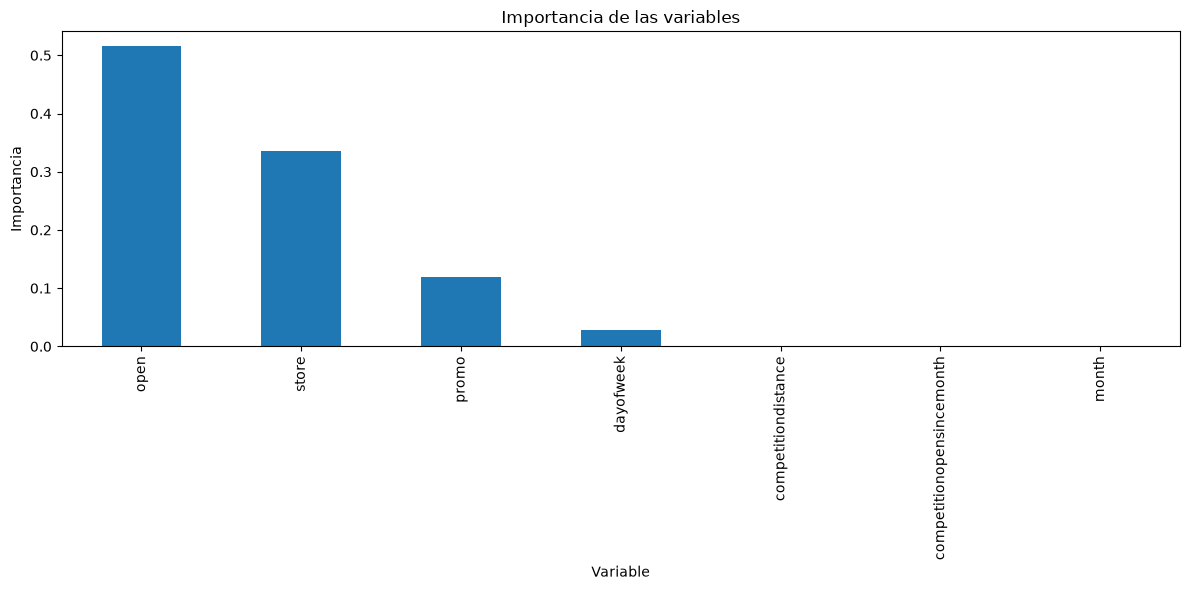

In [93]:
feature_importance.plot(
    kind='bar',
    x='Variable',
    y='Importancia',
    figsize=(12, 6),
    legend=False
)

plt.xticks(rotation=90)
plt.ylabel('Importancia')
plt.title('Importancia de las variables')
plt.tight_layout()
plt.show()

Esquemas del árbol:

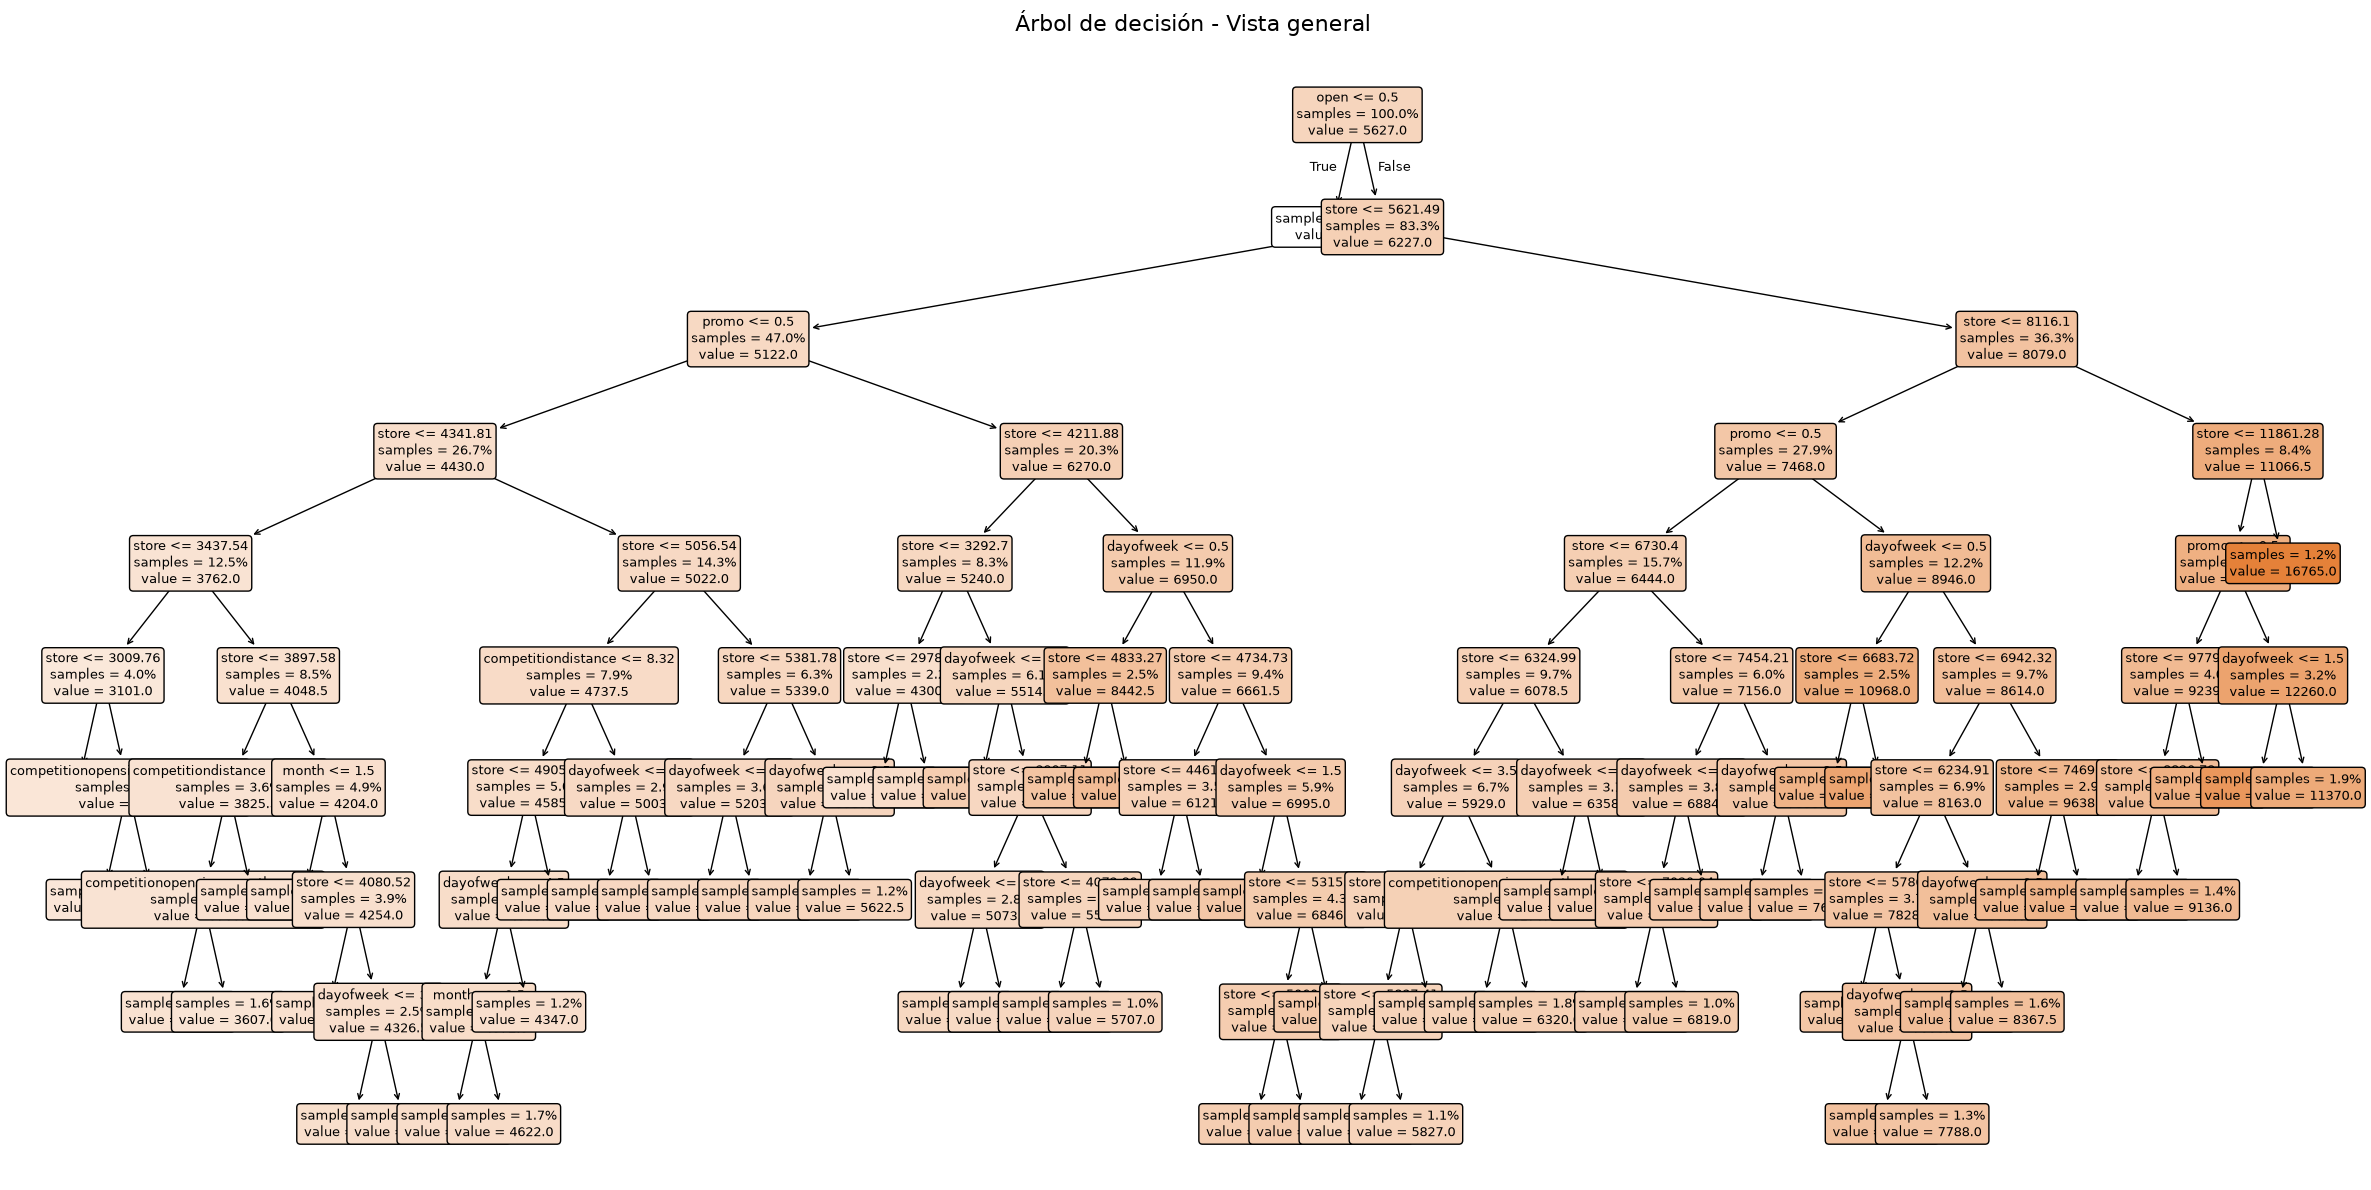

In [94]:
# Crear la figura
fig, ax = plt.subplots(figsize=(24, 12))

plot_tree(
    decision_tree_sin_reduccion,
    max_depth=15,  # Mostrar solo los primeros niveles
    filled=True,
    rounded=True,
    feature_names=nombres_variables,
    fontsize=9,
    proportion=True,
    precision=2,
    impurity=False,
    ax=ax
)

ax.set_title(
    "Árbol de decisión - Vista general",
    fontsize=16,
    pad=20
)

plt.tight_layout()

plt.show()

Reglas en texto:

In [103]:
reglas = export_text(
    decision_tree_sin_reduccion,
    feature_names=list(columns)
)

print(reglas)

|--- open <= 0.50
|   |--- value: [0.00]
|--- open >  0.50
|   |--- store <= 5621.49
|   |   |--- promo <= 0.50
|   |   |   |--- store <= 4341.81
|   |   |   |   |--- store <= 3437.54
|   |   |   |   |   |--- store <= 3009.76
|   |   |   |   |   |   |--- value: [2772.00]
|   |   |   |   |   |--- store >  3009.76
|   |   |   |   |   |   |--- competitionopensincemonth <= 5.50
|   |   |   |   |   |   |   |--- value: [3300.00]
|   |   |   |   |   |   |--- competitionopensincemonth >  5.50
|   |   |   |   |   |   |   |--- value: [3453.50]
|   |   |   |   |--- store >  3437.54
|   |   |   |   |   |--- store <= 3897.58
|   |   |   |   |   |   |--- competitiondistance <= 8.31
|   |   |   |   |   |   |   |--- competitionopensincemonth <= 0.50
|   |   |   |   |   |   |   |   |--- value: [3889.00]
|   |   |   |   |   |   |   |--- competitionopensincemonth >  0.50
|   |   |   |   |   |   |   |   |--- value: [3607.00]
|   |   |   |   |   |   |--- competitiondistance >  8.31
|   |   |   |   |   |   

#### Comparativa de los modelos seleccionados

In [95]:
results

,Modelo,Reducción,Método búsqueda,Mejor score CV,Score entrenamiento CV,Desviación score CV,Brecha train-CV,Mejores parámetros
0,XGBR,Sin reducción,random,0.908316,0.946482,0.002821,0.038166,"{'reduction': 'passthrough', 'model__subsample..."
1,DTR,Sin reducción,random,0.842636,0.852377,0.003986,0.009741,"{'reduction': 'passthrough', 'model__min_sampl..."


In [96]:
results_filtrado = results[
    (results['Modelo'].isin(['DTR', 'XGBR'])) &
    (results['Reducción'] == 'Sin reducción')
]

metricas = ['cv mean test score', 'cv mean train score', 'cv std test score', 'Test average_precision', 'Test cost_loss']

df_largo = results_filtrado.melt(    
    id_vars=['Modelo'],
    value_vars=metricas,
    var_name='Métrica',
    value_name='Valor'
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=df_largo,
    x='Métrica',
    y='Valor',
    hue='Modelo'
)

plt.title('Comparación de métricas: DTC vs ElasticNet')
plt.xlabel('Métrica')
plt.ylabel('Valor')
plt.legend(title='Modelo')
plt.tight_layout()
plt.show()

KeyError: "The following id_vars or value_vars are not present in the DataFrame: ['cv mean test score', 'cv mean train score', 'cv std test score', 'Test average_precision', 'Test cost_loss']"

### Guardado del mejor modelo

#### Arbol interpretable

Modelo:

In [ ]:
# Guardar el modelo entrenado en un archivo .pkl
path_best_ml_model = '../models/decision_tree_sin_reduccion.joblib'
joblib.dump(decision_tree_sin_reduccion, path_best_ml_model)

Pipeline completo.

#### Ensemble XGBoost con mejores metricas:

Modelo:

Pipeline completo:

In [ ]:

# Guardar el modelo entrenado en un archivo .pkl
path_best_ml_model_pipeline = '../models/pipeline_decision_tree_sin_reduccion.pkl'
joblib.dump(pipeline_decision_tree_sin_reduccion, path_best_ml_model_pipeline)

---